# Early dark energy: matter power spectrum

Linear and non-linear matter power spectra in the axion-like early dark energy (EDE) model, from the `ede-v2` emulators (`cosmo_model: 6`), compared with the Boltzmann code they emulate.

The `ede-v2` emulators were trained on `class_ede` (CLASS v3.2.2 with the EDE scalar field, HMcode 2020 dark-matter-only, three degenerate massive neutrinos with $\sum m_\nu = 0.06$ eV) over $0 \le z \le 20$ and $5\times 10^{-4} \le k \le 10\ \mathrm{Mpc}^{-1}$. The EDE parameters are $f_\mathrm{EDE} \in [0.001, 0.5]$, $\log_{10} z_c \in [3, 4.3]$ and $\theta_i \in [0.1, 3.1]$.

Validation on held-out test sets of CLASS-EDE spectra spanning $0 \le z \le 20$ and the full parameter ranges, 95th percentile of $|P_\mathrm{emu}/P_\mathrm{CLASS}-1|$:

| spectrum | $z$ | $k=0.01$ | $k=0.1$ | $k=1$ | $k=10\ \mathrm{Mpc}^{-1}$ |
|---|---|---|---|---|---|
| linear | 0–1 | 0.19% | 0.23% | 0.18% | 0.38% |
| linear | 0–20 | 0.15% | 0.16% | 0.15% | 0.23% |
| non-linear | 0–1 | 0.13% | 0.20% | 0.18% | 0.41% |
| non-linear | 1–3 | 0.08% | 0.17% | 0.14% | 0.25% |
| non-linear | 3–5 | 0.07% | 0.15% | 0.21% | 0.32% |
| non-linear | 5–10 | 0.07% | 0.15% | 0.28% | 0.66% |
| non-linear | 10–20 | 0.10% | 0.17% | 0.39% | 1.28% |

The non-linear emulators (`PKNL_v2`, `PKNLCB_v2`) were retrained in October 2026; versions downloaded before then are inaccurate for $k \gtrsim 0.3\ \mathrm{Mpc}^{-1}$. Update with `git pull` in `class_sz_data_directory/ede`.

The comparison below is at $z = 0, 1, 2$ for $f_\mathrm{EDE} = 0.1$.

The comparison section requires a CLASS build with the EDE module (`class_ede`, or CLASS with the `fEDE`/`log10z_c` shooting) importable as `classy`.

## Cosmology

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from classy_sz import Class as Class_sz

cosmo_params = {
'omega_b': 0.02242,
'omega_cdm': 0.11933,
'H0': 67.66,
'tau_reio': 0.0561,
'ln10^{10}A_s': 3.047,
'n_s': 0.9665,
'fEDE': 0.1,
'log10z_c': 3.562,
'thetai_scf': 2.83,
}

z_list = [0., 1., 2.]

2026-10-26 19:39:23.076082: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## Emulator prediction

In [2]:
%%time
classy_sz = Class_sz()
classy_sz.set(cosmo_params)
classy_sz.set({
'output': 'mPk',
'cosmo_model': 6, # ede-v2
'skip_input': 1,
})
classy_sz.initialize_classy_szfast()

CPU times: user 2.55 s, sys: 0 ns, total: 2.55 s
Wall time: 194 ms


In [3]:
pk_emu = {}
for z in z_list:
    pkl, k = classy_sz.get_pkl_at_z(z, params_values_dict=cosmo_params)
    pknl, _ = classy_sz.get_pknl_at_z(z, params_values_dict=cosmo_params)
    pk_emu[z] = {'lin': np.asarray(pkl).flatten(), 'nl': np.asarray(pknl).flatten()}
k = np.asarray(k)  # in 1/Mpc; P(k) in Mpc^3
print(f'{len(k)} k-values between {k.min():.1e} and {k.max():.1e} 1/Mpc')

1000 k-values between 5.0e-04 and 1.0e+01 1/Mpc


In [4]:
%timeit -n 20 classy_sz.get_pknl_at_z(1., params_values_dict=cosmo_params)

866 μs ± 10.6 μs per loop (mean ± std. dev. of 7 runs, 20 loops each)


## CLASS-EDE reference

Precision settings of the emulator training set. The training set used the PRIMAT 2021 BBN table; a table can be passed through the environment variable `CLASS_SBBN_FILE`, otherwise the CLASS default is used (a change of the primordial helium fraction at the $10^{-4}$ level).

In [5]:
import os
from classy import Class

class_ede_settings = {
'output': 'mPk',
'N_ur': 0.00441,
'N_ncdm': 3,
'm_ncdm': '0.02,0.02,0.02',
'Omega_Lambda': 0.0,
'Omega_fld': 0,
'Omega_scf': -1,
'n_scf': 3,
'CC_scf': 1,
'scf_parameters': '1, 1, 1, 1, 1, 0.0',
'scf_tuning_index': 3,
'attractor_ic_scf': 'no',
'non_linear': 'hmcode',
'hmcode_version': '2020',
'P_k_max_h/Mpc': 100.,
'z_max_pk': 5.,
'recombination': 'HyRec',
'YHe': 'BBN',
'T_cmb': 2.7255,
'perturbations_sampling_stepsize': 0.05,
'radiation_streaming_approximation': 2,
'radiation_streaming_trigger_tau_over_tau_k': 240.,
'ur_fluid_approximation': 2,
'ur_fluid_trigger_tau_over_tau_k': 130.,
'start_large_k_at_tau_h_over_tau_k': 0.05,
'start_small_k_at_tau_c_over_tau_h': 0.0004,
'start_sources_at_tau_c_over_tau_h': 0.006,
'tight_coupling_trigger_tau_c_over_tau_h': 0.005,
'tight_coupling_trigger_tau_c_over_tau_k': 0.008,
'tol_ncdm_synchronous': 1.e-6,
'l_max_g': 40,
'l_max_pol_g': 60,
'l_max_ur': 35,
'l_max_ncdm': 30,
}
if os.getenv('CLASS_SBBN_FILE'):
    class_ede_settings['sBBN file'] = os.getenv('CLASS_SBBN_FILE')

The non-linear `pk` of this CLASS-EDE build intermittently returns the linear spectrum without raising an error. The function below recomputes until the HMcode boost $P_\mathrm{nl}/P_\mathrm{lin}$ at $k = 1\ \mathrm{Mpc}^{-1}$ differs from unity at every requested redshift.

In [6]:
def class_ede_pk(params, z_list, k, max_tries=10):
    for attempt in range(1, max_tries + 1):
        cosmo = Class()
        cosmo.set(class_ede_settings)
        cosmo.set(params)
        cosmo.compute()
        out = {z: {'lin': np.array([cosmo.pk_lin(kk, z) for kk in k]),
                   'nl': np.array([cosmo.pk(kk, z) for kk in k])} for z in z_list}
        boost = [cosmo.pk(1., z) / cosmo.pk_lin(1., z) for z in z_list]
        cosmo.struct_cleanup()
        if min(boost) > 1.01:
            print(f'HMcode boost at k=1/Mpc: {np.round(boost, 3)} (attempt {attempt})')
            return out
        print(f'attempt {attempt}: linear spectrum returned at some z (boost {np.round(boost, 3)}), recomputing')
    raise RuntimeError('non-linear spectrum not obtained')

In [7]:
%%time
pk_class = class_ede_pk(cosmo_params, z_list, k)

HMcode boost at k=1/Mpc: [8.946 4.67  2.741] (attempt 1)
CPU times: user 41 s, sys: 162 ms, total: 41.2 s
Wall time: 4.49 s


## Comparison

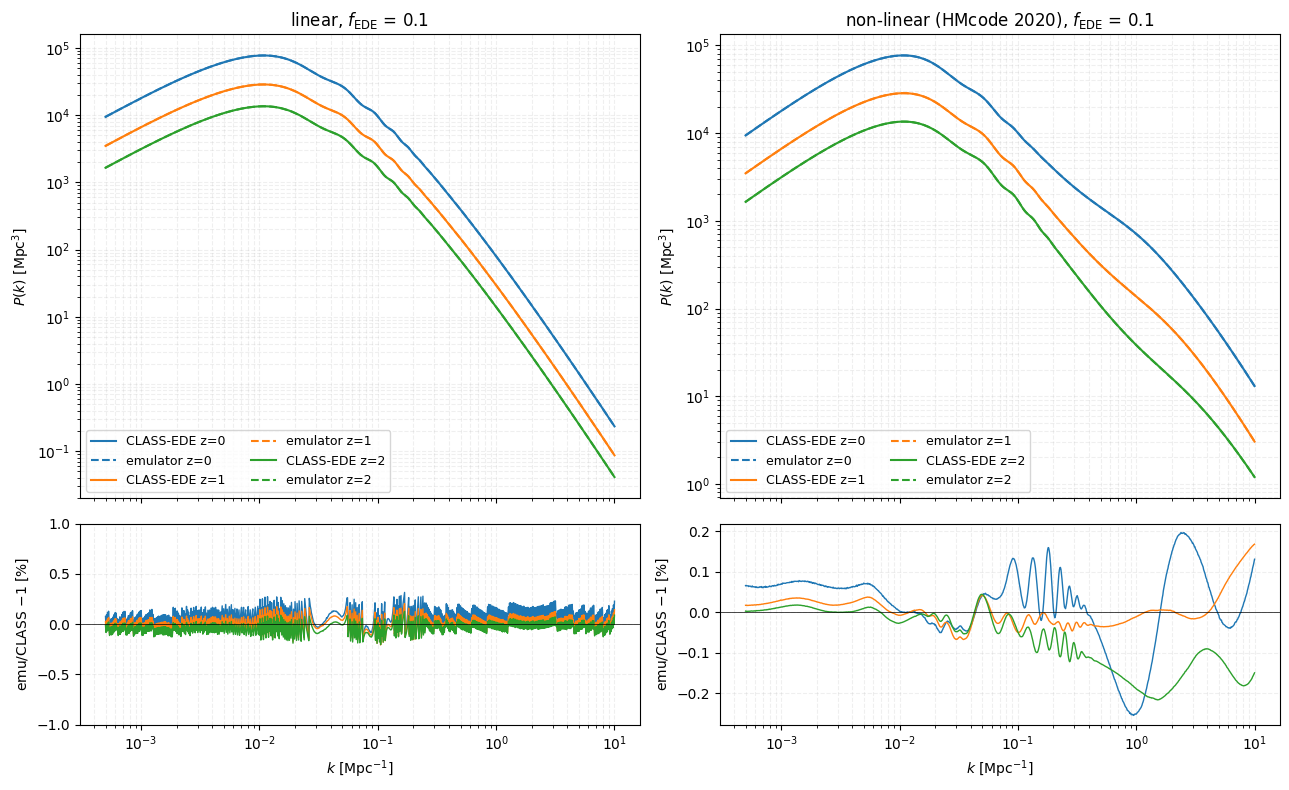

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
for j, (kind, title) in enumerate([('lin', 'linear'), ('nl', 'non-linear (HMcode 2020)')]):
    ax, axr = axes[0, j], axes[1, j]
    for z, c in zip(z_list, ['C0', 'C1', 'C2']):
        ax.loglog(k, pk_class[z][kind], c=c, lw=1.5, label=f'CLASS-EDE z={z:g}')
        ax.loglog(k, pk_emu[z][kind], c=c, ls='--', lw=1.5, label=f'emulator z={z:g}')
        axr.semilogx(k, 100 * (pk_emu[z][kind] / pk_class[z][kind] - 1.), c=c, lw=1)
    ax.set_title(fr'{title}, $f_\mathrm{{EDE}}$ = {cosmo_params["fEDE"]:g}')
    ax.set_ylabel(r'$P(k)\ [\mathrm{Mpc}^3]$')
    ax.legend(fontsize=9, ncol=2)
    ax.grid(which='both', alpha=0.2, ls='--')
    axr.axhline(0, c='k', lw=0.5)
    axr.set_ylabel(r'emu/CLASS $-1$ [%]')
    axr.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$')
    axr.grid(which='both', alpha=0.2, ls='--')
axes[1, 0].set_ylim(-1, 1)
plt.tight_layout()

In [9]:
print(f"{'':12s}{'z':>4s}" + ''.join(f'{f"k={kk:g}":>10s}' for kk in (0.01, 0.1, 1., 10.)))
for kind in ('lin', 'nl'):
    for z in z_list:
        r = 100 * (pk_emu[z][kind] / pk_class[z][kind] - 1.)
        print(f'{kind:12s}{z:4g}' + ''.join(f'{r[np.argmin(abs(k - kk))]:10.3f}' for kk in (0.01, 0.1, 1., 10.)))
print('emu/CLASS - 1 in %')

               z    k=0.01     k=0.1       k=1      k=10
lin            0    -0.020    -0.021     0.037     0.227
lin            1    -0.066    -0.068    -0.034     0.143
lin            2    -0.111    -0.095    -0.059     0.088
nl             0     0.003     0.099    -0.252     0.131
nl             1    -0.007    -0.049    -0.011     0.168
nl             2    -0.027    -0.047    -0.190    -0.150
emu/CLASS - 1 in %
